# 01e — De documentos a recuperación: trocear, buscar y medir

[![](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Adamychen/m10_quarto/blob/main/notebooks/bloque1/01e-recuperacion.ipynb)

> Este tema forma parte del Bloque 1 — Fundamentos. Se recomienda haber
> visto [01c-embeddings.qmd](01c-embeddings.qmd) y
> [01d-vectordb.qmd](01d-vectordb.qmd) primero.

> **Qué aprenderás**
>
> En 01c y 01d hemos visto cómo convertir texto en vectores y
> guardarlos. Falta lo que decide, en la práctica, si un buscador sirve
> o no:
>
> - **Trocear** los documentos largos (*chunking*) y por qué el tamaño
>   importa.
> - **Buscar con palabras** (BM25), **con significado** (embeddings) y
>   **con las dos a la vez** (búsqueda híbrida).
> - **Medir** si la recuperación funciona, con métricas que puedas
>   calcular tú mismo.
>
> Este es el puente entre la teoría del bloque y el [HPD
> 1](hpd1-embeddings.qmd), y la base de todo el RAG del Bloque 3.

In [1]:
!pip install -q sentence-transformers langchain-text-splitters matplotlib

In [2]:
import os
os.environ["TOKENIZERS_PARALLELISM"] = "false"
import warnings
warnings.filterwarnings("ignore")
import math
import re
from collections import Counter
import numpy as np
from sentence_transformers import SentenceTransformer

modelo = SentenceTransformer("paraphrase-multilingual-MiniLM-L12-v2")
print("Modelo cargado.")

Modelo cargado.

## El pipeline completo

<figure id="fig-pipeline-recuperacion">
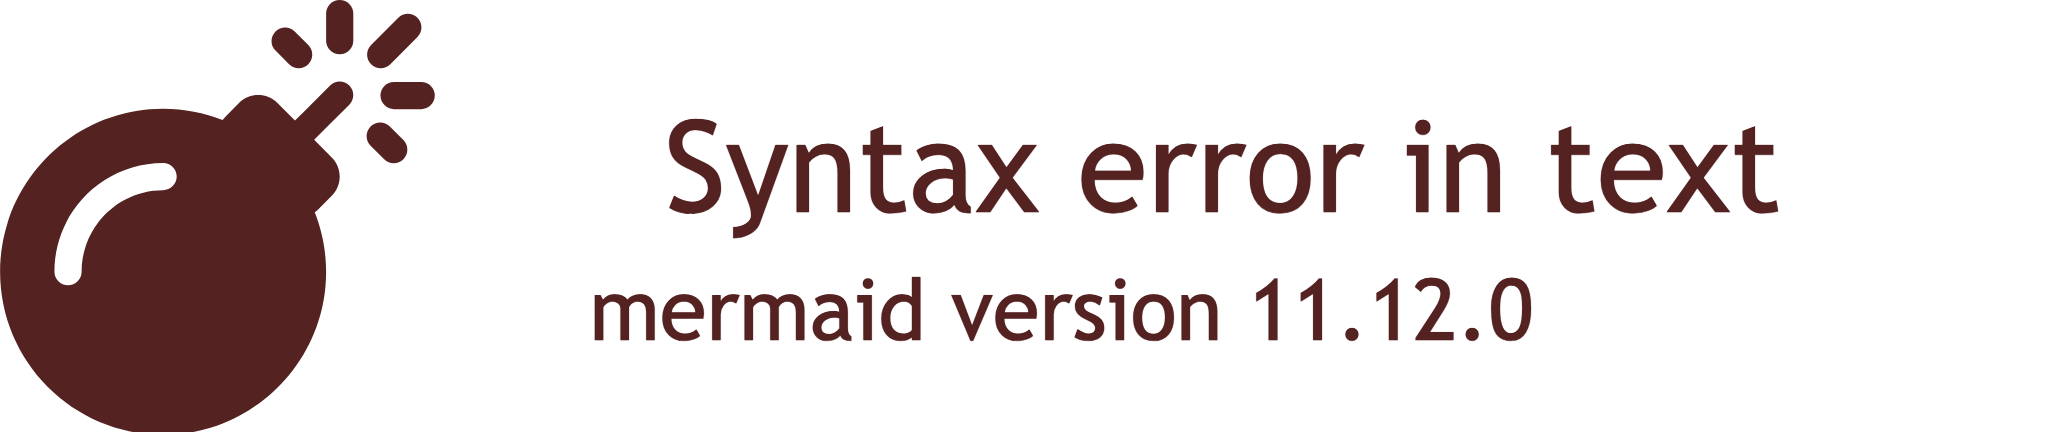
<figcaption>Figura 1</figcaption>
</figure>

En 01c y 01d trabajamos con frases cortas, que ya eran la unidad de
búsqueda. Los documentos reales (contratos, manuales, artículos) son
mucho más largos que el límite de tokens de un modelo de embeddings, y
además contienen muchos temas. Antes de indexarlos hay que partirlos.

## Trocear documentos: el tamaño del chunk importa

Un *chunk* es un fragmento del documento que se indexa por separado.
Tres razones obligan a trocear:

1.  **El límite del modelo.** Lo que supera el límite de tokens no se ve
    (Caso 5 de [01c](01c-embeddings.qmd#sec-fallo-truncado)).
2.  **La dilución.** El embedding de un texto largo es una especie de
    promedio: si habla de cinco temas, no representa bien ninguno.
3.  **El coste.** Cada chunk recuperado se pasa al LLM (ver [Tokens,
    dinero y memoria](01b-llms.qmd#sec-tokens-coste-memoria) en 01b);
    cuanto más texto sobrante, más caro y más fácil que el modelo se
    distraiga.

Pero partir demasiado también rompe cosas: si la respuesta queda cortada
entre dos fragmentos, ninguno la contiene entera. Lo vemos con un
contrato breve del banco y seis preguntas cuya respuesta sabemos dónde
está.

In [3]:
contrato = """Objeto. Estas condiciones regulan la cuenta corriente del cliente y los servicios asociados de banca digital.

Comisiones. El mantenimiento de la cuenta es gratuito si el cliente tiene la nómina domiciliada; en caso contrario se cobrarán 3 euros al mes. Las transferencias SEPA cuestan 0,50 euros por operación y las transferencias internacionales el 2 % del importe, con un mínimo de 5 euros.

Tarjetas. La tarjeta de débito se emite sin coste. En caso de pérdida o robo, el cliente debe bloquearla de inmediato desde la app o llamando al teléfono de atención 24 horas. El banco no será responsable de los cargos posteriores a la comunicación.

Límites. El límite diario de retirada en cajeros es de 600 euros y el de pagos con tarjeta es de 3.000 euros por operación. Los límites pueden ampliarse temporalmente previa solicitud en la app.

Seguridad. Para cambiar la contraseña, el cliente accede a Ajustes > Seguridad. El banco nunca solicitará claves por teléfono ni por correo electrónico.

Reclamaciones. El cliente puede reclamar durante un año mediante el formulario web. El banco responderá en un máximo de 15 días hábiles.

Cancelación. El cliente puede cancelar la cuenta en cualquier momento sin penalización, siempre que el saldo sea cero. El banco podrá cancelarla con un preaviso de 30 días."""

# (pregunta, fragmento exacto que contiene la respuesta)
preguntas_contrato = [
    ("¿Cuánto cuesta mantener la cuenta si no tengo nómina?", "3 euros al mes"),
    ("¿Qué tengo que hacer si me roban la tarjeta?", "bloquearla de inmediato"),
    ("¿Cuál es el límite para pagar con tarjeta?", "3.000 euros por operación"),
    ("¿En cuántos días me responden una reclamación?", "15 días hábiles"),
    ("¿Cuánto preaviso da el banco para cancelar mi cuenta?", "30 días"),
    ("¿Cobran un mínimo en las transferencias internacionales?", "mínimo de 5 euros"),
]
print(f"El contrato tiene {len(contrato)} caracteres y {len(preguntas_contrato)} preguntas de prueba.")

El contrato tiene 1306 caracteres y 6 preguntas de prueba.

Ahora partimos el contrato con distintos tamaños y medimos dos cosas:
(1) si el chunk más parecido a la pregunta **contiene** la respuesta y
(2) **cuánto texto** le entregaríamos al LLM.

In [4]:
from langchain_text_splitters import RecursiveCharacterTextSplitter

print(f"{'chunk_size':>10} {'overlap':>8} {'nº chunks':>10} {'car./chunk':>11} {'tokens/chunk':>13} {'acierto top-1':>14}")
for tamano, solape in [(80, 0), (150, 20), (300, 50), (600, 100), (1200, 200), (5000, 0)]:
    splitter = RecursiveCharacterTextSplitter(chunk_size=tamano, chunk_overlap=solape)
    chunks = splitter.split_text(contrato)
    emb = modelo.encode(chunks, normalize_embeddings=True)
    aciertos = 0
    for pregunta, evidencia in preguntas_contrato:
        q = modelo.encode([pregunta], normalize_embeddings=True)
        mejor = chunks[int(np.argmax((q @ emb.T)[0]))]
        aciertos += evidencia in mejor
    tokens = np.mean([len(modelo.tokenizer(c)["input_ids"]) for c in chunks])
    print(f"{tamano:>10} {solape:>8} {len(chunks):>10} {np.mean([len(c) for c in chunks]):>11.0f} {tokens:>13.0f} {aciertos:>11}/{len(preguntas_contrato)}")
print(f"\nLímite del modelo de embeddings: {modelo.max_seq_length} tokens")

chunk_size  overlap  nº chunks  car./chunk  tokens/chunk  acierto top-1
        80        0         20          64            16           1/6

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (248 > 128). Running this sequence through the model will result in indexing errors

       150       20         13         107            26           4/6
       300       50          6         216            50           6/6
       600      100          3         434            97           6/6
      1200      200          2         721           160           6/6
      5000        0          1        1306           288           6/6

Límite del modelo de embeddings: 128 tokens

Cómo leer la tabla:

- **Chunks muy pequeños (80–150 caracteres):** la respuesta queda
  partida entre fragmentos y el acierto se hunde (1 de 6 y 4 de 6).
- **Chunks medianos (300–600 caracteres):** acierto completo y cada
  chunk entrega solo un párrafo, y cabe en el límite del modelo.
- **Chunks enormes (1.200 y 5.000 caracteres):** el acierto es perfecto,
  **pero es una ilusión de este ejemplo**: con un solo documento
  pequeño, devolver “todo” siempre contiene la respuesta. Fíjate en las
  dos columnas de al lado: el LLM recibiría el contrato entero para
  responder una pregunta de una línea, y los chunks de más de 128 tokens
  superan el límite del modelo, así que su parte final ni siquiera
  cuenta en el embedding.

No hay un tamaño universal. Para texto normal, entre 200 y 1.000
caracteres (o 100–300 tokens) con un solape del 10–20 % es un punto de
partida razonable. **Lo que decide es medirlo con tus preguntas**
(ejercicio A2 del HPD 1).

> **¿Para qué sirve el solapamiento?**
>
> Si cortas justo en mitad de una frase importante, ninguno de los dos
> chunks la contiene. El solape repite el final de un chunk al principio
> del siguiente. Cuesta algo de espacio extra pero protege las
> fronteras. La demo [Trocear documentos para
> RAG](../demos/chunking.qmd) te deja ajustar tamaño y solape y ver
> cuándo se parte la respuesta.

## Buscar con palabras: BM25

Los embeddings entienden paráfrasis, pero fallan con códigos, siglas y
cifras (casos 2 y 3 de [01c](01c-embeddings.qmd#sec-cuando-fallan)).
Para eso existe una familia de métodos mucho más antigua y todavía
imbatible en lo suyo: la **búsqueda léxica**. Su representante estándar
es **BM25** (Robertson & Zaragoza, 2009), una evolución de TF-IDF que:

- da más peso a las palabras **raras** (IDF), como TF-IDF;
- hace que repetir una palabra muchas veces aporte cada vez menos (la
  saturación, controlada por $k_1$);
- penaliza los documentos largos respecto a los cortos (controlado por
  $b$).

$$
\operatorname{BM25}(q, d) = \sum_{t \in q} \operatorname{IDF}(t) \cdot \frac{f(t,d)\,(k_1+1)}{f(t,d) + k_1\left(1 - b + b\,\frac{|d|}{\text{avgdl}}\right)}
$$

donde $f(t,d)$ es cuántas veces aparece el término $t$ en el documento
$d$, $|d|$ su longitud y $\text{avgdl}$ la longitud media. Son 15 líneas
de Python:

In [5]:
PALABRAS_VACIAS = set("el la los las un una unos unas de del al a en y o que qué me mi tu te se es por con para si su sus lo como cuánto cuál cómo cada".split())

def tokenizar(texto):
    palabras = re.findall(r"[a-záéíóúñü0-9\-]+", texto.lower())
    return [p for p in palabras if p not in PALABRAS_VACIAS]

class BM25:
    def __init__(self, documentos, k1=1.5, b=0.75):
        self.docs = [tokenizar(d) for d in documentos]
        self.k1, self.b = k1, b
        self.N = len(self.docs)
        self.avgdl = sum(len(d) for d in self.docs) / self.N
        self.df = Counter(p for d in self.docs for p in set(d))

    def idf(self, palabra):
        return math.log(1 + (self.N - self.df[palabra] + 0.5) / (self.df[palabra] + 0.5))

    def puntuaciones(self, consulta):
        resultado = np.zeros(self.N)
        for i, doc in enumerate(self.docs):
            frecuencias = Counter(doc)
            for p in tokenizar(consulta):
                if p in frecuencias:
                    f = frecuencias[p]
                    norm = f + self.k1 * (1 - self.b + self.b * len(doc) / self.avgdl)
                    resultado[i] += self.idf(p) * f * (self.k1 + 1) / norm
        return resultado
print("BM25 listo.")

BM25 listo.

Lo probamos sobre el buscador de preguntas frecuentes (el mismo corpus
de 01c y 01d):

In [6]:
faq = [
    "Puedes pagar con tarjeta de crédito o débito en cualquier comercio adherido.",
    "No se admite el pago con tarjeta en operaciones superiores a 3.000 euros; usa transferencia.",
    "Para pedir un reembolso, solicita la devolución en la app en un plazo de 14 días.",
    "La comisión por transferencia SEPA es de 0,50 euros por operación.",
    "Las transferencias internacionales tienen una comisión del 2 % del importe.",
    "Si pierdes tu tarjeta, bloquéala desde la app o llama al teléfono de atención 24 horas.",
    "El IBAN es el código que identifica tu cuenta bancaria en transferencias nacionales e internacionales.",
    "Para cambiar tu contraseña, entra en Ajustes > Seguridad y pulsa «Restablecer».",
    "El límite diario de retirada en cajeros es de 600 euros.",
    "Abrir una cuenta nueva es gratis y se completa en cinco minutos con tu DNI.",
    "Los préstamos personales se conceden en 24 horas si tienes la nómina domiciliada.",
    "La hipoteca a tipo variable se revisa cada seis meses según el Euríbor.",
    "Error E-4021: la operación fue rechazada por saldo insuficiente.",
    "Error E-4012: la tarjeta ha caducado y debe renovarse.",
]
bm25 = BM25(faq)
emb_faq = modelo.encode(faq, normalize_embeddings=True)

def top_lexico(consulta, k=2):
    p = bm25.puntuaciones(consulta)
    return [(int(i), float(p[i])) for i in np.argsort(-p)[:k] if p[i] > 0]

def top_denso(consulta, k=2):
    p = (modelo.encode([consulta], normalize_embeddings=True) @ emb_faq.T)[0]
    return [(int(i), float(p[i])) for i in np.argsort(-p)[:k]]

for consulta in ["¿qué significa el error E-4012?", "Euríbor", "he olvidado mi clave de acceso"]:
    print(f"\nConsulta: {consulta}")
    print("  BM25 :", [(i, round(s, 2)) for i, s in top_lexico(consulta)] or "sin coincidencias")
    print("  Denso:", [(i, round(s, 2)) for i, s in top_denso(consulta)])


Consulta: ¿qué significa el error E-4012?
  BM25 : [(13, 4.31), (12, 1.88)]
  Denso: [(12, 0.68), (13, 0.59)]

Consulta: Euríbor
  BM25 : [(11, 2.28)]
  Denso: [(6, 0.18), (8, 0.17)]

Consulta: he olvidado mi clave de acceso
  BM25 : sin coincidencias
  Denso: [(7, 0.52), (13, 0.38)]

Fíjate en el patrón:

- `E-4012` y `Euríbor` son identificadores y nombres propios: BM25 los
  encuentra al instante; el embedding puede dudar (en el primer caso
  devuelve antes el documento `E-4021`).
- «clave de acceso» no comparte ninguna palabra con «contraseña»: BM25
  **no encuentra nada**, el embedding sí.

Cada método falla donde el otro acierta. De ahí la idea más práctica de
esta página.

## Búsqueda híbrida: lo mejor de los dos mundos

Combinar los dos rankings tiene un problema: las puntuaciones no son
comparables (BM25 va de 0 a decenas, el coseno de 0 a 1). Una solución
sencilla y robusta es **ignorar las puntuaciones y fusionar solo las
posiciones**: *Reciprocal Rank Fusion* (RRF) (Cormack et al., 2009).
Cada documento recibe $\frac{1}{c + \text{posición}}$ en cada ranking
(con $c = 60$ habitualmente) y se suman:

$$
\operatorname{RRF}(d) = \sum_{r \in \text{rankings}} \frac{1}{c + \operatorname{pos}_r(d)}
$$

Un documento que aparece arriba en **los dos** rankings gana; uno que
solo aparece en uno, queda en medio.

In [7]:
def ranking_lexico(consulta):
    p = bm25.puntuaciones(consulta)
    return [int(i) for i in np.argsort(-p) if p[i] > 0]       # solo documentos con alguna coincidencia

def ranking_denso(consulta):
    p = (modelo.encode([consulta], normalize_embeddings=True) @ emb_faq.T)[0]
    return [int(i) for i in np.argsort(-p)]

def ranking_hibrido(consulta, c=60):
    puntos = Counter()
    for ranking in (ranking_lexico(consulta), ranking_denso(consulta)):
        for posicion, doc in enumerate(ranking, start=1):
            puntos[doc] += 1 / (c + posicion)
    return [doc for doc, _ in puntos.most_common()]

print("Híbrido para «¿qué significa el error E-4012?»:", ranking_hibrido("¿qué significa el error E-4012?")[:3])

Híbrido para «¿qué significa el error E-4012?»: [13, 12, 3]

## Medir: ¿funciona la recuperación?

Hasta ahora hemos mirado ejemplos sueltos. Para decidir entre métodos
necesitamos un **conjunto de prueba**: preguntas para las que sabemos
qué documento es el correcto (el *ground truth*, que construye una
persona). Las métricas más usadas son:

| Métrica | Qué responde | Cuándo usarla |
|------------------------|------------------------|------------------------|
| **hit@k** | ¿Hay al menos un documento relevante entre los $k$ primeros? | Cuando basta con encontrar *una* respuesta buena (casi todo RAG) |
| **recall@k** | ¿Qué fracción de **todos** los relevantes está en los $k$ primeros? | Cuando hay varios documentos relevantes y quieres encontrarlos todos |
| **MRR** (*mean reciprocal rank*) | ¿En qué posición aparece el primer relevante? Promedio de $1/\text{posición}$ | Cuando importa que el primero sea bueno |

Tabla 1: Métricas de recuperación más usadas

Una trampa clásica: si una pregunta tiene **2 documentos relevantes** y
evalúas con $k=1$, el recall@1 solo puede valer 0,5 como máximo, aunque
el sistema sea perfecto. Con $k$ pequeño suele ser más informativo el
hit@k.

Construimos 12 preguntas de prueba sobre el buscador del banco (algunas
con paráfrasis, otras con códigos y nombres propios) y comparamos los
tres métodos:

In [8]:
# (pregunta, índice del documento correcto en `faq`)
prueba = [
    ("¿qué significa el error E-4012?", 13), ("error E-4021", 12),
    ("Quiero que me devuelvan el dinero de una compra", 2), ("he olvidado mi clave de acceso", 7),
    ("¿Cuánto cuesta una transferencia SEPA?", 3), ("¿Cómo bloqueo mi tarjeta si la pierdo?", 5),
    ("¿Qué es el IBAN?", 6), ("¿Cada cuánto se revisa la hipoteca variable?", 11),
    ("comisión del 2 % en transferencias internacionales", 4), ("Euríbor", 11),
    ("rechazo por falta de fondos", 12), ("mi plástico caducó", 13),
]

def posicion_correcta(ranking, correcto):
    return ranking.index(correcto) + 1 if correcto in ranking else None   # None = no aparece

def evaluar(funcion_ranking):
    posiciones = [posicion_correcta(funcion_ranking(q), c) for q, c in prueba]
    hit1 = np.mean([p == 1 for p in posiciones])
    hit3 = np.mean([p is not None and p <= 3 for p in posiciones])
    mrr = np.mean([1 / p if p else 0 for p in posiciones])
    return hit1, hit3, mrr

print(f"{'Método':<10} {'hit@1':>6} {'hit@3':>6} {'MRR':>6}")
for nombre, f in [("BM25", ranking_lexico), ("Denso", ranking_denso), ("Híbrido", ranking_hibrido)]:
    h1, h3, mrr = evaluar(f)
    print(f"{nombre:<10} {h1:>6.2f} {h3:>6.2f} {mrr:>6.2f}")

Método      hit@1  hit@3    MRR
BM25         0.58   0.67   0.61
Denso        0.75   0.92   0.85
Híbrido      0.83   1.00   0.92

Con esta prueba pequeña, el patrón es el esperado: **BM25 solo se queda
corto** (no encuentra paráfrasis), **el denso falla en códigos y nombres
propios**, y **la fusión mejora a los dos**. Cuidado con sacar
conclusiones fuertes: son solo 12 preguntas que hemos escrito nosotros,
y con un conjunto tan pequeño una pregunta cambia las cifras en 8
puntos. Para decidir en un proyecto real hacen falta más preguntas,
escritas por quienes usarán el sistema.

> **El ground truth define lo que mides**
>
> Define cuál es “el documento correcto” **por su contenido** (por
> ejemplo, “el chunk que contiene la frase X”), nunca por una posición o
> un identificador que cambia si modificas el tamaño del chunk. Si cada
> vez que cambias el troceado cambian los identificadores, tus métricas
> dejan de ser comparables. Es el error más común al evaluar un pipeline
> de recuperación, y el HPD 1 te lo hará comprobar.

## Qué hacer cuando no hay respuesta

Todo lo anterior supone que la respuesta existe en el corpus. En la
práctica, muchas preguntas no la tienen, y el buscador devolverá
igualmente los $k$ vecinos más cercanos (Caso 6 de
[01c](01c-embeddings.qmd#sec-fallo-sin-respuesta)). Dos defensas
habituales:

- **Umbral de similitud, calibrado.** Probando con preguntas con y sin
  respuesta, elige el valor del coseno por debajo del cual no pasas el
  resultado al LLM. Es específico de cada modelo y corpus.
- **Pedir al LLM que diga «no lo sé»** cuando el contexto no contiene la
  respuesta, y evaluarlo (Bloque 3, con RAGAS, y [Bloque
  4](../bloque4/04b-alucinaciones.qmd)).

## Comprueba lo aprendido

> **Indexas manuales de 80 páginas sin trocear. ¿Qué dos cosas pueden ir
> mal?**
>
> Primero, el modelo de embeddings solo ve los primeros 128–512 tokens
> (según el modelo), así que casi todo el manual es invisible. Segundo,
> aunque lo viera, el embedding de un texto con decenas de temas no
> representa bien ninguno, y cada resultado entregaría al LLM un manual
> entero.

> **Los usuarios de tu buscador escriben mucho referencias de pedido
> como «PED-2024-00871». ¿Qué método usarías y por qué?**
>
> Búsqueda léxica (BM25) o, mejor, híbrida. Los identificadores exactos
> son terreno de la coincidencia de palabras; un embedding trataría
> «PED-2024-00871» y «PED-2024-00817» como casi idénticos.

> **Tu hit@3 pasa de 0,83 a 0,92 al cambiar de método sobre 12
> preguntas. ¿Es una mejora real?**
>
> Probablemente no se pueda afirmar. Con 12 preguntas, 0,83 → 0,92 es
> una sola pregunta más acertada. Habría que repetir con más preguntas
> (decenas o cientos) y mirar si la mejora es consistente.

> **En una evaluación cada pregunta tiene 3 documentos relevantes.
> Calculas recall@1 y obtienes 0,33 como máximo. ¿Es un fallo del
> sistema?**
>
> No. Con $k=1$ solo puedes recuperar 1 de los 3 relevantes, así que 1/3
> es el máximo posible. Para esa evaluación conviene recall@3 o hit@1.

------------------------------------------------------------------------

> Ya tienes todas las piezas teóricas del bloque. Pasa al taller: **[HPD
> 1 — Pipeline de embeddings y búsqueda
> semántica](hpd1-embeddings.qmd)**.

## Referencias de esta página

- Robertson & Zaragoza (2009)
- Cormack et al. (2009)
- Karpukhin et al. (2020)

# References

Cormack, G. V., Clarke, C. L. A., & Buettcher, S. (2009). Reciprocal
Rank Fusion Outperforms Condorcet and Individual Rank Learning Methods.
*Proceedings of the 32nd International ACM SIGIR Conference on Research
and Development in Information Retrieval*, 758-759.
<https://doi.org/10.1145/1571941.1572114>

Karpukhin, V., Oguz, B., Min, S., Lewis, P., Wu, L., Edunov, S., Chen,
D., & Yih, W. (2020). Dense Passage Retrieval for Open-Domain Question
Answering. *Proceedings of the 2020 Conference on Empirical Methods in
Natural Language Processing (EMNLP)*, 6769-6781.
<https://doi.org/10.18653/v1/2020.emnlp-main.550>

Robertson, S., & Zaragoza, H. (2009). The Probabilistic Relevance
Framework: BM25 and Beyond. *Foundations and Trends in Information
Retrieval*, *3*(4), 333-389. <https://doi.org/10.1561/1500000019>